In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
import seaborn as sns

In [2]:
data = np.load('cifar-10-python.npz')

X_train = data["x_train"]
y_train = data["y_train"]
X_test = data["x_test"]
y_test = data["y_test"]

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (50000, 32, 32, 3)
Training labels: (50000,)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000,)


In [3]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Pixel range:", X_train.min(), "to", X_train.max())

Pixel range: 0.0 to 1.0


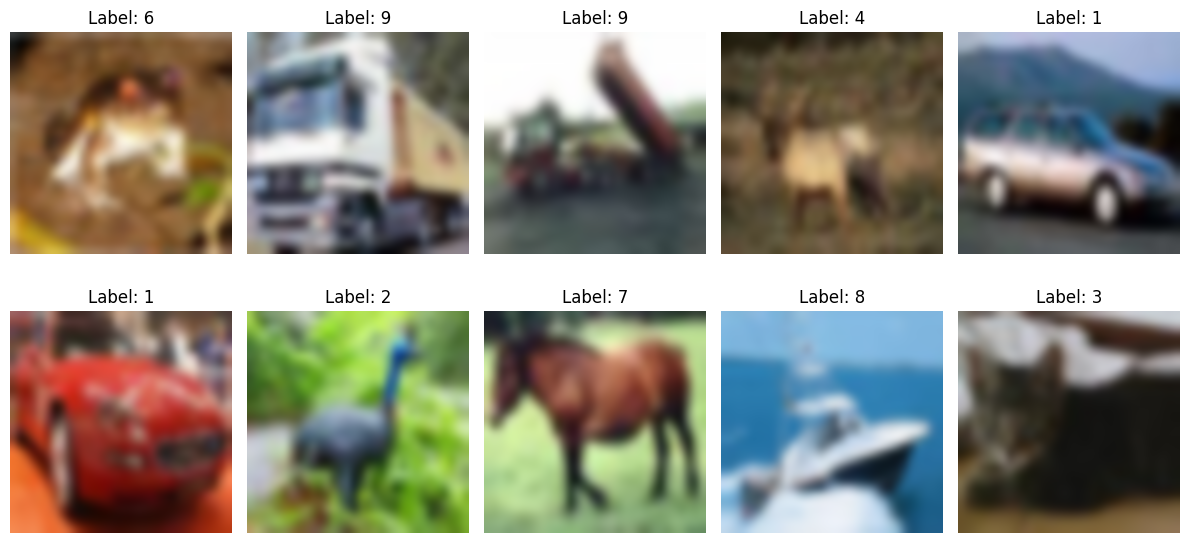

In [4]:
# Display sample training images before assigning class names

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], interpolation="bicubic")
    plt.title(f"Label: {int(y_train[i].flatten()[0])}")
    plt.axis("off")

plt.tight_layout()
plt.show()


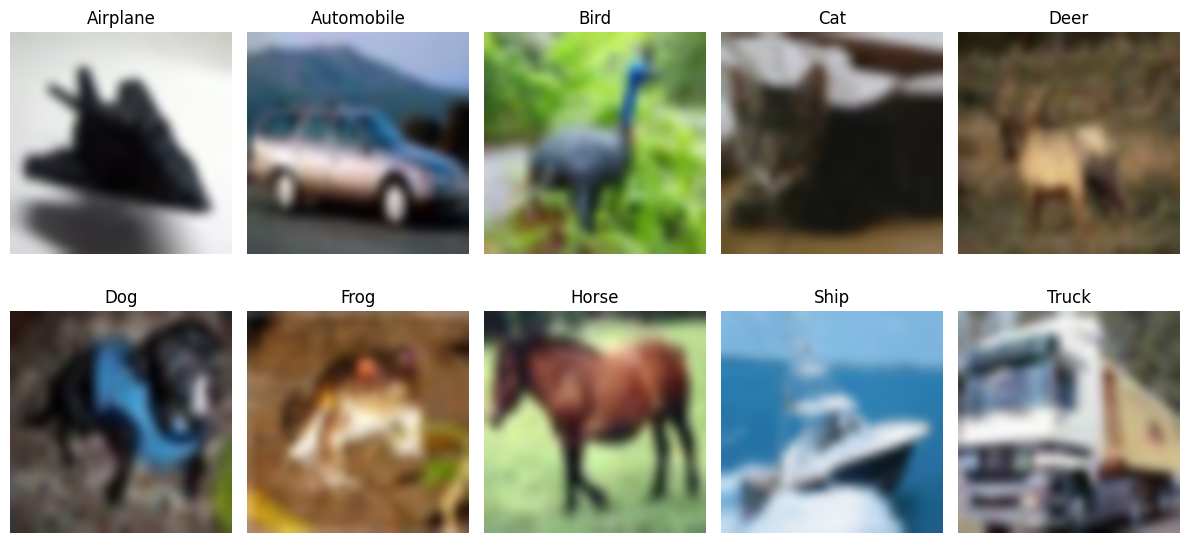

In [5]:
class_names = ["Airplane", "Automobile", "Bird", "Cat", "Deer","Dog", "Frog", "Horse", "Ship", "Truck"]

plt.figure(figsize=(12, 6))

for i in range(10):
    index = np.where(y_train.flatten() == i)[0][0]

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[index], interpolation="bicubic")
    plt.title(class_names[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    ),
    layers.RandomZoom(0.1)
])

In [7]:
model1 = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),

    data_augmentation,

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model1.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 32, 32, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2304)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │         147,520 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 167,562 (654.54 KB)

 Trainable params: 167,562 (654.54 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model2 = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),

    data_augmentation,

    layers.Conv2D(32, (3, 3), padding="same",
                  activation="relu"),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), padding="same",
                  activation="relu"),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

model2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 32, 32, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 32, 32, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 30, 30, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 15, 15, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 13, 13, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 2304)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         295,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 361,898 (1.38 MB)

 Trainable params: 361,898 (1.38 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [10]:
early_stop1 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

In [11]:
history1 = model1.fit(
    X_train, y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop1]
)

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.3658 - loss: 1.7375 - val_accuracy: 0.4442 - val_loss: 1.5966
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.4722 - loss: 1.4726 - val_accuracy: 0.5222 - val_loss: 1.3448
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.5140 - loss: 1.3617 - val_accuracy: 0.5150 - val_loss: 1.3644
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.5459 - loss: 1.2899 - val_accuracy: 0.5824 - val_loss: 1.2042
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.5630 - loss: 1.2340 - val_accuracy: 0.6044 - val_loss: 1.1107
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.5741 - loss: 1.2055 - val_accuracy: 0.5730 - val_loss: 1.2632
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.5886 - loss: 1.1690 - val_accuracy: 0.6236 - val_loss: 1.0962
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.5995 - loss: 1.1473 - v

In [12]:
early_stop2 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

In [13]:
history2 = model2.fit(
    X_train, y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop2]
)

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 23s 31ms/step - accuracy: 0.3206 - loss: 1.8276 - val_accuracy: 0.4320 - val_loss: 1.5271
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 22s 31ms/step - accuracy: 0.4428 - loss: 1.5302 - val_accuracy: 0.5124 - val_loss: 1.3399
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 22s 31ms/step - accuracy: 0.4912 - loss: 1.4173 - val_accuracy: 0.5572 - val_loss: 1.2180
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 22s 31ms/step - accuracy: 0.5237 - loss: 1.3397 - val_accuracy: 0.5960 - val_loss: 1.1218
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 22s 32ms/step - accuracy: 0.5398 - loss: 1.2895 - val_accuracy: 0.5986 - val_loss: 1.1366
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 22s 31ms/step - accuracy: 0.5555 - loss: 1.2475 - val_accuracy: 0.6058 - val_loss: 1.1331
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 22s 31ms/step - accuracy: 0.5741 - loss: 1.2073 - val_accuracy: 0.6128 - val_loss: 1.1293
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 24s 34ms/step - accuracy: 0.5836 - loss: 1.1874 - 

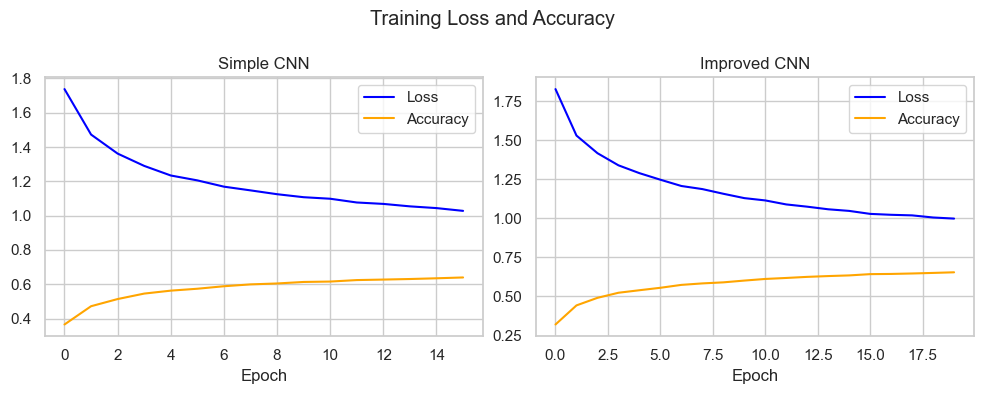

In [14]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Model 1
axes[0].plot(history1.history["loss"], color="blue", label="Loss")
axes[0].plot(history1.history["accuracy"], color="orange", label="Accuracy")
axes[0].set_title("Simple CNN")
axes[0].set_xlabel("Epoch")
axes[0].legend()

# Model 2
axes[1].plot(history2.history["loss"], color="blue", label="Loss")
axes[1].plot(history2.history["accuracy"], color="orange", label="Accuracy")
axes[1].set_title("Improved CNN")
axes[1].set_xlabel("Epoch")
axes[1].legend()

fig.suptitle("Training Loss and Accuracy")
plt.tight_layout()
plt.show()

In [15]:
test_loss1, test_acc1 = model1.evaluate(X_test, y_test, verbose=0)
test_loss2, test_acc2 = model2.evaluate(X_test, y_test, verbose=0)

print("Simple CNN")
print(f"Test Loss: {test_loss1:.4f}")
print(f"Test Accuracy: {test_acc1 * 100:.2f}%")

print("\nImproved CNN")
print(f"Test Loss: {test_loss2:.4f}")
print(f"Test Accuracy: {test_acc2 * 100:.2f}%")

Simple CNN
Test Loss: 0.9912
Test Accuracy: 66.00%

Improved CNN
Test Loss: 0.8553
Test Accuracy: 70.35%


In [16]:
results = pd.DataFrame({
    "Model": ["Simple CNN", "Improved CNN"],
    "Test Loss": [test_loss1, test_loss2],
    "Test Accuracy (%)": [test_acc1 * 100, test_acc2 * 100]
})

print(results.round(2).to_string(index=False))

       Model  Test Loss  Test Accuracy (%)
  Simple CNN       0.99              66.00
Improved CNN       0.86              70.35


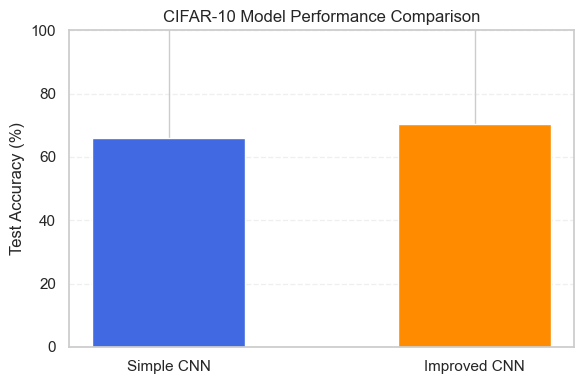

In [17]:
plt.figure(figsize=(6, 4))

plt.bar(
    ["Simple CNN", "Improved CNN"],
    [test_acc1 * 100, test_acc2 * 100],
    color=["royalblue", "darkorange"],
    width=0.5
)

plt.ylabel("Test Accuracy (%)")
plt.title("CIFAR-10 Model Performance Comparison")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
if test_acc1 > test_acc2:
    print("Simple CNN performs better.")
elif test_acc2 > test_acc1:
    print("Improved CNN performs better.")
else:
    print("Both models have the same test accuracy.")

Improved CNN performs better.


Enter an index between 0 and 9999:  7


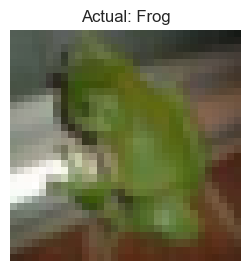

Actual Class: Frog

Model 1: Simple CNN
Predicted Class: Frog
Confidence: 66.83%
Correct Prediction!

Model 2: Improved CNN
Predicted Class: Frog
Confidence: 82.31%
Correct Prediction!


In [19]:
index = int(input("Enter an index between 0 and 9999: "))

if 0 <= index < len(X_test):

    image = X_test[index]
    actual_label = int(y_test[index].flatten()[0])

    # Predict using both models
    pred1 = model1.predict(image.reshape(1, 32, 32, 3), verbose=0)
    pred2 = model2.predict(image.reshape(1, 32, 32, 3), verbose=0)

    predicted1 = np.argmax(pred1[0])
    predicted2 = np.argmax(pred2[0])

    # Display the image
    plt.figure(figsize=(3, 3))
    plt.imshow(image)
    plt.title(f"Actual: {class_names[actual_label]}")
    plt.axis("off")
    plt.show()

    # Model 1 result
    print("Actual Class:", class_names[actual_label])
    print("\nModel 1: Simple CNN")
    print("Predicted Class:", class_names[predicted1])
    print(f"Confidence: {np.max(pred1[0]) * 100:.2f}%")
    print("Correct Prediction!" if predicted1 == actual_label
          else "Incorrect Prediction!")

    # Model 2 result
    print("\nModel 2: Improved CNN")
    print("Predicted Class:", class_names[predicted2])
    print(f"Confidence: {np.max(pred2[0]) * 100:.2f}%")
    print("Correct Prediction!" if predicted2 == actual_label
          else "Incorrect Prediction!")

else:
    print("Invalid index! Enter a number from 0 to 9999.")